<a href="https://colab.research.google.com/github/Vnooo13/college/blob/main/Jurnal_EP_GRU_Hsig_02.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#DATA Awal


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime
from scipy import stats
import gdown

In [ ]:
# 1. Pastikan kita membaca kembali dataset lengkapnya
df_full = pd.read_csv('/content/gelombang_merge_2019_2025 (4).csv')
df_full.head()

,Time(UTC/GMT),Hsig(m),Hsig(Scale),Hmax(m),Hmax(Scale),WaveDir(deg),WaveDir(compass),PrimSwell(m),PrimSwell(Scale),PrimSwellDir(deg),...,WindSeaDir(compass),WavePeriod(s),SurfCurrentSpd(cm/s),SurfCurrentDir,SurfCurrentDir(compass),SeaSurfaceTemperature(°C),SeaSurfaceSalinity(PSU),WindSpeed(knots),WindDir(deg),WindDir(compass)
0,2019-01-01 00:00:00,1.44698,Moderate,2.38622,Moderate,295,WNW,0.0,Smooth,296,...,W,5,45.0,94,E,28.912500,33.301500,12,307,NW
1,2019-01-01 03:00:00,1.40283,Moderate,2.31767,Moderate,295,WNW,0.0,Smooth,296,...,W,5,44.0,94,E,28.894687,33.289187,12,307,NW
2,2019-01-01 06:00:00,1.35867,Moderate,2.24912,Moderate,296,WNW,0.0,Smooth,296,...,W,5,44.0,95,E,28.876875,33.276875,12,307,NW
3,2019-01-01 09:00:00,1.31452,Moderate,2.18058,Moderate,296,WNW,0.0,Smooth,296,...,W,5,44.0,96,E,28.859063,33.264562,12,307,NW
4,2019-01-01 12:00:00,1.27036,Moderate,2.11203,Moderate,296,WNW,0.0,Smooth,296,...,W,5,43.0,96,E,28.841250,33.252250,12,307,NW


In [ ]:
df_full.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20463 entries, 0 to 20462
Data columns (total 24 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Time(UTC/GMT)              20463 non-null  object 
 1   Hsig(m)                    20463 non-null  float64
 2   Hsig(Scale)                20463 non-null  object 
 3   Hmax(m)                    20463 non-null  float64
 4   Hmax(Scale)                20463 non-null  object 
 5   WaveDir(deg)               20463 non-null  int64  
 6   WaveDir(compass)           20463 non-null  object 
 7   PrimSwell(m)               20463 non-null  float64
 8   PrimSwell(Scale)           20463 non-null  object 
 9   PrimSwellDir(deg)          20463 non-null  int64  
 10  PrimSwellDir(compass)      20463 non-null  object 
 11  WindSea(m)                 20463 non-null  float64
 12  WindSea(Scale)             20463 non-null  object 
 13  WindSeaDir(deg)            20463 non-null  int

## DROP

In [ ]:
# Menentukan kolom yang mengandung kata 'compass' atau 'Scale'
cols_to_drop = [col for col in df_full.columns if 'compass' in col or 'Scale' in col]

# Hapus Hmax
cols_to_drop.extend(['Hmax(m)','SeaSurfaceSalinity(PSU)'])

# Hapus kolom dari df_full jika ada di dataset
cols_to_drop = [col for col in cols_to_drop if col in df_full.columns]
df_full = df_full.drop(columns=cols_to_drop)

# Menampilkan informasi kolom yang tersisa
print(f"Kolom yang dihapus: {cols_to_drop}")
print(f"\nJumlah kolom sekarang: {df_full.shape[1]}")
df_full.info()

Kolom yang dihapus: ['Hsig(Scale)', 'Hmax(Scale)', 'WaveDir(compass)', 'PrimSwell(Scale)', 'PrimSwellDir(compass)', 'WindSea(Scale)', 'WindSeaDir(compass)', 'SurfCurrentDir(compass)', 'WindDir(compass)', 'Hmax(m)', 'SeaSurfaceSalinity(PSU)']

Jumlah kolom sekarang: 13
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20463 entries, 0 to 20462
Data columns (total 13 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Time(UTC/GMT)              20463 non-null  object 
 1   Hsig(m)                    20463 non-null  float64
 2   WaveDir(deg)               20463 non-null  int64  
 3   PrimSwell(m)               20463 non-null  float64
 4   PrimSwellDir(deg)          20463 non-null  int64  
 5   WindSea(m)                 20463 non-null  float64
 6   WindSeaDir(deg)            20463 non-null  int64  
 7   WavePeriod(s)              20463 non-null  int64  
 8   SurfCurrentSpd(cm/s)       20463 non-null  float64
 9   S

In [ ]:
df_full.describe()

,Hsig(m),WaveDir(deg),PrimSwell(m),PrimSwellDir(deg),WindSea(m),WindSeaDir(deg),WavePeriod(s),SurfCurrentSpd(cm/s),SurfCurrentDir,SeaSurfaceTemperature(°C),WindSpeed(knots),WindDir(deg)
count,20463.000000,20463.000000,20463.000000,20463.000000,20463.000000,20463.000000,20463.000000,20463.000000,20463.000000,20463.000000,20463.000000,20463.000000
mean,0.609096,170.900454,0.089553,188.011826,0.493790,230.663246,4.222450,22.774364,187.704540,29.310012,9.405806,162.022528
std,0.420241,97.883658,0.128793,83.379196,0.456293,60.721162,0.769349,20.412411,101.848868,1.931895,4.294790,85.562502
min,0.000000,2.000000,0.000000,4.000000,0.000000,2.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.277230,87.000000,0.000000,92.000000,0.052680,190.000000,4.000000,14.000000,88.000000,28.829187,6.000000,100.000000
50%,0.569940,97.000000,0.027340,182.000000,0.410810,270.000000,4.000000,20.000000,227.000000,29.492750,10.000000,112.000000
75%,0.881195,288.000000,0.136545,270.000000,0.830710,270.000000,5.000000,29.000000,282.000000,30.076656,12.000000,265.000000
max,2.985590,360.000000,0.892750,360.000000,2.415690,355.000000,10.000000,926.000000,360.000000,31.726500,24.000000,360.000000


## Degree

In [ ]:
import numpy as np

# Kolom arah dalam derajat
degree_cols = ['WaveDir(deg)', 'PrimSwellDir(deg)', 'WindSeaDir(deg)', 'SurfCurrentDir', 'WindDir(deg)']

# Transformasi ke sine dan cosine
for col in degree_cols:
    rad = np.radians(df_full[col])
    df_full[f'{col}_sin'] = np.sin(rad)
    df_full[f'{col}_cos'] = np.cos(rad)

# Menghapus kolom derajat asli
df_full = df_full.drop(columns=degree_cols)

# Menampilkan kolom-kolom baru
df_full.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20463 entries, 0 to 20462
Data columns (total 18 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Time(UTC/GMT)              20463 non-null  object 
 1   Hsig(m)                    20463 non-null  float64
 2   PrimSwell(m)               20463 non-null  float64
 3   WindSea(m)                 20463 non-null  float64
 4   WavePeriod(s)              20463 non-null  int64  
 5   SurfCurrentSpd(cm/s)       20463 non-null  float64
 6   SeaSurfaceTemperature(°C)  20463 non-null  float64
 7   WindSpeed(knots)           20463 non-null  int64  
 8   WaveDir(deg)_sin           20463 non-null  float64
 9   WaveDir(deg)_cos           20463 non-null  float64
 10  PrimSwellDir(deg)_sin      20463 non-null  float64
 11  PrimSwellDir(deg)_cos      20463 non-null  float64
 12  WindSeaDir(deg)_sin        20463 non-null  float64
 13  WindSeaDir(deg)_cos        20463 non-null  flo

#DATA PREPOS_01

In [ ]:
# 1. Konversi Time(UTC/GMT) menjadi Datetime dan set sebagai Index
df_full['Time(UTC/GMT)'] = pd.to_datetime(df_full['Time(UTC/GMT)'])
df_full = df_full.sort_values('Time(UTC/GMT)').set_index('Time(UTC/GMT)')

# 2. Penanganan Data Kotor (Hapus baris dengan kode error 9999 atau missing > 10%)
has_9999 = (df_full == 9999).any(axis=1)
missing_ratio = df_full.isnull().mean(axis=1)
rows_to_drop = has_9999 | (missing_ratio > 0.10)

if rows_to_drop.sum() > 0:
    print(f"Menghapus {rows_to_drop.sum()} baris kotor (error 9999 / missing > 10%)")
    df_full = df_full[~rows_to_drop]

# 3. Imputasi rata-rata lokal jika ada missing <= 10%
if df_full.isnull().sum().sum() > 0:
    df_full = df_full.fillna(df_full.rolling(window=8, min_periods=1).mean()).bfill().ffill()

print(f"✓ Selesai. Total baris bersih di df_full: {len(df_full)} baris, {df_full.shape[1]} kolom.")

✓ Selesai. Total baris bersih di df_full: 20463 baris, 17 kolom.


In [ ]:
df_full.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 20463 entries, 2019-01-01 00:00:00 to 2026-01-01 00:00:00
Data columns (total 17 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Hsig(m)                    20463 non-null  float64
 1   PrimSwell(m)               20463 non-null  float64
 2   WindSea(m)                 20463 non-null  float64
 3   WavePeriod(s)              20463 non-null  int64  
 4   SurfCurrentSpd(cm/s)       20463 non-null  float64
 5   SeaSurfaceTemperature(°C)  20463 non-null  float64
 6   WindSpeed(knots)           20463 non-null  int64  
 7   WaveDir(deg)_sin           20463 non-null  float64
 8   WaveDir(deg)_cos           20463 non-null  float64
 9   PrimSwellDir(deg)_sin      20463 non-null  float64
 10  PrimSwellDir(deg)_cos      20463 non-null  float64
 11  WindSeaDir(deg)_sin        20463 non-null  float64
 12  WindSeaDir(deg)_cos        20463 non-null  float64
 13  SurfCurrent

# **MODEL EP-GRU**

In [ ]:
import torch
import torch.nn as nn

Successfully renamed PrivateUse1 backend to 'tpu'. Device: device(type='tpu')
Registered Python module for 'tpu'.
Device type: tpu, Device index: default
Initializing TPU distributed runtime


In [ ]:
class EPGRUCell(nn.Module):
    """
    Error-Projected GRU Cell Murni (Deterministik)
    - Innovation Signal: e_t = x_t @ W_e - h_{t-1}
    - Injeksi e_t ke Reset Gate, Update Gate, dan Candidate State
    """
    def __init__(self, input_dim: int, hidden_dim: int):
        super().__init__()
        self.input_dim = input_dim
        self.hidden_dim = hidden_dim

        # Matriks Proyeksi Galat (W_e)
        self.w_innov = nn.Linear(input_dim, hidden_dim, bias=False)

        # Bobot Reset Gate & Update Gate
        self.w_ih_gates = nn.Linear(input_dim, 2 * hidden_dim)
        self.w_hh_gates = nn.Linear(hidden_dim, 2 * hidden_dim, bias=False)
        self.w_eh_gates = nn.Linear(hidden_dim, 2 * hidden_dim, bias=False)

        # Bobot Candidate State
        self.w_ih_cand = nn.Linear(input_dim, hidden_dim)
        self.w_hh_cand = nn.Linear(hidden_dim, hidden_dim, bias=False)
        self.w_eh_cand = nn.Linear(hidden_dim, hidden_dim, bias=False)

        self._reset_parameters()

    def _reset_parameters(self):
        for name, param in self.named_parameters():
            if 'weight' in name:
                nn.init.xavier_uniform_(param)
            elif 'bias' in name:
                nn.init.zeros_(param)

    def forward(self, x_t: torch.Tensor, h_prev: torch.Tensor):
        # 1. Innovation Signal
        e_t = self.w_innov(x_t) - h_prev

        # 2. Reset & Update Gates
        gates = self.w_ih_gates(x_t) + self.w_hh_gates(h_prev) + self.w_eh_gates(e_t)
        r_gate, z_gate = gates.chunk(2, dim=-1)
        r_t = torch.sigmoid(r_gate)
        z_t = torch.sigmoid(z_gate)

        # 3. Candidate Hidden State
        h_cand = torch.tanh(
            self.w_ih_cand(x_t) + r_t * (self.w_hh_cand(h_prev) + self.w_eh_cand(e_t))
        )

        # 4. Final Hidden State
        h_t = (1.0 - z_t) * h_prev + z_t * h_cand
        return h_t


In [ ]:
class EPGRUModel(nn.Module):
    """
    Arsitektur 2-Layer Stacked EP-GRU Murni
    - Layer 1: 64 unit (return sequences)
    - Layer 2: 32 unit
    - Output : Linear 2 unit -> [WindSpeed, Hsig]
    """
    def __init__(self, input_dim: int = 18, hidden_dim1: int = 64,
                 hidden_dim2: int = 32, output_dim: int = 2):
        super().__init__()
        self.hidden_dim1 = hidden_dim1
        self.hidden_dim2 = hidden_dim2

        self.cell1 = EPGRUCell(input_dim, hidden_dim1)
        self.cell2 = EPGRUCell(hidden_dim1, hidden_dim2)
        self.fc_out = nn.Linear(hidden_dim2, output_dim)

    def forward(self, x: torch.Tensor):
        batch_size, seq_len, _ = x.shape
        device = x.device

        h1_t = torch.zeros(batch_size, self.hidden_dim1, device=device)
        h2_t = torch.zeros(batch_size, self.hidden_dim2, device=device)

        for t in range(seq_len):
            h1_t = self.cell1(x[:, t, :], h1_t)
            h2_t = self.cell2(h1_t, h2_t)

        return self.fc_out(h2_t)

# TARGET

In [ ]:
from sklearn.preprocessing import MinMaxScaler
from torch.utils.data import DataLoader, TensorDataset

In [ ]:
# ==============================================================================
# 1. PREPARASI DATA (17 FITUR -> 2 TARGET), NORMALISASI, & SLIDING WINDOW (24)
# ==============================================================================
target_cols = ['WindSpeed(knots)', 'Hsig(m)']
feature_cols = list(df_full.columns)  # 17 kolom fitur di df_full (Time sudah jadi index)

print(f"Total Fitur Input (X) : {len(feature_cols)} fitur")
print(f"Total Target Output (y): {len(target_cols)} target -> {target_cols}")

raw_X = df_full[feature_cols].values
raw_y = df_full[target_cols].values

# Split kronologis 80% Train dan 20% Test untuk mencegah lookahead bias (Subbab 3.2.3.c)
split_raw_idx = int(len(df_full) * 0.8)

scaler_X = MinMaxScaler(feature_range=(0, 1))
scaler_y = MinMaxScaler(feature_range=(0, 1))

# Fit MinMaxScaler hanya pada bagian data latih
scaler_X.fit(raw_X[:split_raw_idx])
scaler_y.fit(raw_y[:split_raw_idx])

scaled_X = scaler_X.transform(raw_X)
scaled_y = scaler_y.transform(raw_y)

def create_multivariate_sequences(data_X, data_y, seq_len=24):
    X, y = [], []
    for i in range(len(data_X) - seq_len):
        X.append(data_X[i : i + seq_len])
        y.append(data_y[i + seq_len])
    return np.array(X), np.array(y)

SEQ_LEN = 24  # Lookback window 24 timestep (72 jam)
X_all, y_all = create_multivariate_sequences(scaled_X, scaled_y, seq_len=SEQ_LEN)

# Pembagian Kronologis: 80% Data Latih & 20% Data Uji
split_idx = int(len(X_all) * 0.8)
X_train_full, X_test = X_all[:split_idx], X_all[split_idx:]
y_train_full, y_test = y_all[:split_idx], y_all[split_idx:]

# Alokasi 10% subset validasi (validation_split = 0.1) dari Data Latih (Subbab 3.2.3.c)
val_split_idx = int(len(X_train_full) * 0.9)
X_train, X_val = X_train_full[:val_split_idx], X_train_full[val_split_idx:]
y_train, y_val = y_train_full[:val_split_idx], y_train_full[val_split_idx:]

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
BATCH_SIZE = 32  # Sesuai Subbab 3.2.3.b

train_dataset = TensorDataset(torch.FloatTensor(X_train), torch.FloatTensor(y_train))
val_dataset   = TensorDataset(torch.FloatTensor(X_val), torch.FloatTensor(y_val))
test_dataset  = TensorDataset(torch.FloatTensor(X_test), torch.FloatTensor(y_test))

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
val_loader   = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)
test_loader  = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

print(f"Device       : {device}")
print(f"X_train shape: {X_train.shape} | y_train shape: {y_train.shape}")
print(f"X_val shape  : {X_val.shape}   | y_val shape  : {y_val.shape}")
print(f"X_test shape : {X_test.shape}  | y_test shape : {y_test.shape}")

Total Fitur Input (X) : 17 fitur
Total Target Output (y): 2 target -> ['WindSpeed(knots)', 'Hsig(m)']
Device       : cpu
X_train shape: (14715, 24, 17) | y_train shape: (14715, 2)
X_val shape  : (1636, 24, 17)   | y_val shape  : (1636, 2)
X_test shape : (4088, 24, 17)  | y_test shape : (4088, 2)


# VISUALISASI

In [ ]:
# ==============================================================================
# VISUALISASI DIAGRAM TAHAPAN METODOLOGI PENELITIAN (TAHAP 4, 5, & 6)
# ==============================================================================
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import numpy as np

# Konfigurasi style font default
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['DejaVu Sans', 'Arial']


# VIZ. SLIDING WINDOW

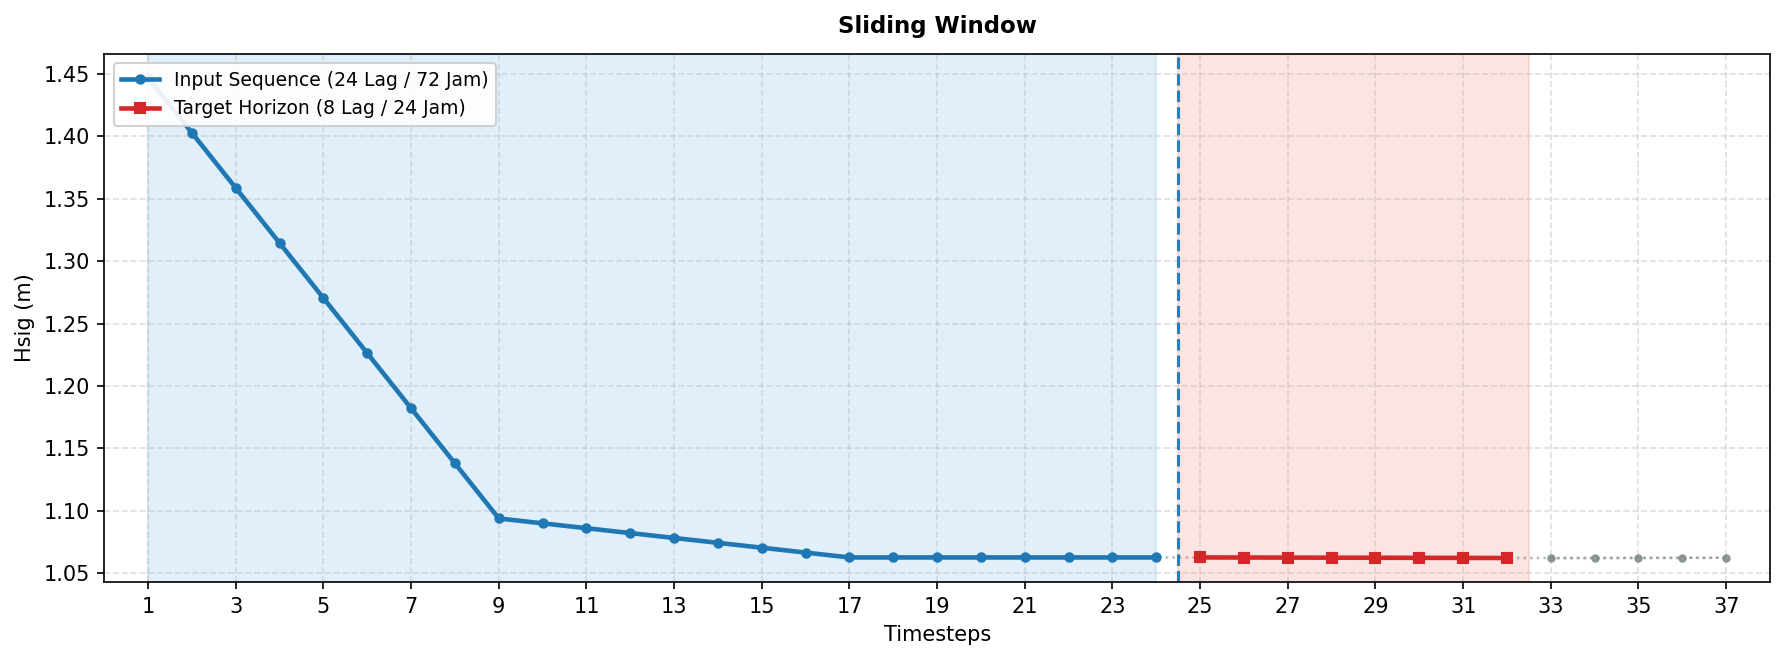

In [ ]:
# ==============================================================================
# VISUALISASI SLIDING WINDOW (INPUT 24 LAG -> TARGET 8 LAG)
# ==============================================================================
import matplotlib.pyplot as plt
import numpy as np

# Ambil data sampai timestep 37
n_points = 37
hsig_sample = df_full['Hsig(m)'].values[:n_points]
time_steps = np.arange(1, n_points + 1)

plt.figure(figsize=(12, 4.5), dpi=150)

# Garis data observasi penuh
plt.plot(time_steps, hsig_sample, color='#7f8c8d', lw=1.2, linestyle=':', marker='.', alpha=0.6)

# Input Sequence: 24 lag pertama (t=1 s.d. 24)
plt.plot(time_steps[:24], hsig_sample[:24], color='#1f77b4', lw=2.2, marker='o', markersize=4,
         label='Input Sequence (24 Lag / 72 Jam)')
plt.axvspan(1, 24, color='#3498db', alpha=0.15)
plt.axvline(24.5, color='#2980b9', linestyle='--', lw=1.5)

# Target Horizon: 8 lag berikutnya (t=25 s.d. 32)
plt.plot(time_steps[24:32], hsig_sample[24:32], color='#d62728', lw=2.2, marker='s', markersize=4.5,
         label='Target Horizon (8 Lag / 24 Jam)')
plt.axvspan(24.5, 32.5, color='#e74c3c', alpha=0.15)

# Sisa data pembanding (t=33 s.d. 37)
plt.plot(time_steps[32:], hsig_sample[32:], color='#7f8c8d', lw=1.2, linestyle=':', marker='.', alpha=0.6)

plt.title('Sliding Window', fontsize=11, fontweight='bold', pad=10)
plt.xlabel('Timesteps', fontsize=10)
plt.ylabel('Hsig (m)', fontsize=10)
plt.xlim(0, 38)
plt.xticks(range(1, 38, 2))
plt.grid(True, linestyle='--', alpha=0.4)
plt.legend(loc='upper left', framealpha=0.9, fontsize=9)
plt.tight_layout()
plt.show()

In [ ]:
# Cek bentuk array sampel ke-0
print("Bentuk 1 sampel Input X[0]  :", X_train[0].shape)  # Output: (24, 18)
print("Bentuk 1 sampel Target y[0] :", y_train[0].shape)  # Output: (2,)

# Tampilkan data historis 24 langkah untuk fitur pertama
print("\nIsi sekuens 24 langkah historis fitur pertama (X[0, :, 0]):")
print(X_train[0, :, 0])

# Tampilkan nilai target pasangannya
print("\nNilai target yang harus ditebak (y[0]):")
print(y_train[0])

Bentuk 1 sampel Input X[0]  : (24, 17)
Bentuk 1 sampel Target y[0] : (2,)

Isi sekuens 24 langkah historis fitur pertama (X[0, :, 0]):
[0.48465462 0.46986693 0.45507588 0.44028818 0.42549714 0.41070944
 0.39592174 0.3811307  0.366343   0.36503338 0.3637271  0.36241748
 0.36110785 0.35980158 0.35849196 0.35718568 0.35587606 0.35587606
 0.35587606 0.35587606 0.35587606 0.35587606 0.35587606 0.35587606]

Nilai target yang harus ditebak (y[0]):
[0.5        0.35587606]


In [ ]:
# Ubah balok tensor X_train[0] berdimensi (24, 17) menjadi DataFrame
df_sample_0 = pd.DataFrame(
    data=X_train[0],
    columns=feature_cols,
    index=[f"Lag t-{23 - i}" if (23 - i) > 0 else "Saat ini (t0)" for i in range(24)]
)

print(f"Bentuk Balok Matriks: {df_sample_0.shape} (24 Baris x 17 Kolom)")
print("\n=== DATA BALOK 1 SAMPEL MASUKAN (X[0]) ===")
display(df_sample_0.head(6)) # Menampilkan 6 lag terawal
display(df_sample_0.tail(6)) # Menampilkan 6 lag terakhir menjelang target

Bentuk Balok Matriks: (24, 17) (24 Baris x 17 Kolom)

=== DATA BALOK 1 SAMPEL MASUKAN (X[0]) ===


,Hsig(m),PrimSwell(m),WindSea(m),WavePeriod(s),SurfCurrentSpd(cm/s),SeaSurfaceTemperature(°C),WindSpeed(knots),WaveDir(deg)_sin,WaveDir(deg)_cos,PrimSwellDir(deg)_sin,PrimSwellDir(deg)_cos,WindSeaDir(deg)_sin,WindSeaDir(deg)_cos,SurfCurrentDir_sin,SurfCurrentDir_cos,WindDir(deg)_sin,WindDir(deg)_cos
Lag t-23,0.484655,0.0,0.589219,0.375,0.048596,0.911304,0.5,0.046846,0.711309,0.050603,0.719186,0.0,0.500953,0.998782,0.465122,0.100682,0.800908
Lag t-22,0.469867,0.0,0.572164,0.375,0.047516,0.910743,0.5,0.046846,0.711309,0.050603,0.719186,0.0,0.500953,0.998782,0.465122,0.100682,0.800908
Lag t-21,0.455076,0.0,0.555104,0.375,0.047516,0.910182,0.5,0.050603,0.719186,0.050603,0.719186,0.0,0.500953,0.998097,0.456422,0.100682,0.800908
Lag t-20,0.440288,0.0,0.538049,0.375,0.047516,0.909620,0.5,0.050603,0.719186,0.050603,0.719186,0.0,0.500953,0.997261,0.447736,0.100682,0.800908
Lag t-19,0.425497,0.0,0.520994,0.375,0.046436,0.909059,0.5,0.050603,0.719186,0.050603,0.719186,0.0,0.500953,0.997261,0.447736,0.100682,0.800908
Lag t-18,0.410709,0.0,0.503939,0.375,0.045356,0.908497,0.5,0.050603,0.719186,0.054497,0.726995,0.0,0.500953,0.997261,0.447736,0.100682,0.800908


,Hsig(m),PrimSwell(m),WindSea(m),WavePeriod(s),SurfCurrentSpd(cm/s),SeaSurfaceTemperature(°C),WindSpeed(knots),WaveDir(deg)_sin,WaveDir(deg)_cos,PrimSwellDir(deg)_sin,PrimSwellDir(deg)_cos,WindSeaDir(deg)_sin,WindSeaDir(deg)_cos,SurfCurrentDir_sin,SurfCurrentDir_cos,WindDir(deg)_sin,WindDir(deg)_cos
Lag t-5,0.355876,0.0,0.438525,0.375,0.036717,0.902444,0.5,0.036408,0.687303,0.036408,0.687303,0.0,0.500953,0.989074,0.396044,0.100682,0.800908
Lag t-4,0.355876,0.0,0.437875,0.375,0.035637,0.902142,0.5,0.036408,0.687303,0.036408,0.687303,0.0,0.500953,0.989074,0.396044,0.100682,0.800908
Lag t-3,0.355876,0.0,0.437221,0.375,0.034557,0.901841,0.5,0.036408,0.687303,0.036408,0.687303,0.0,0.500953,0.989074,0.396044,0.100682,0.800908
Lag t-2,0.355876,0.0,0.436567,0.375,0.033477,0.901539,0.5,0.036408,0.687303,0.036408,0.687303,0.0,0.500953,0.987185,0.387524,0.100682,0.800908
Lag t-1,0.355876,0.0,0.435917,0.375,0.032397,0.901238,0.5,0.036408,0.687303,0.036408,0.687303,0.0,0.500953,0.987185,0.387524,0.100682,0.800908
Saat ini (t0),0.355876,0.0,0.435263,0.375,0.031317,0.900937,0.5,0.033210,0.679184,0.033210,0.679184,0.0,0.500953,0.987185,0.387524,0.100682,0.800908


=== RENTANG NILAI FITUR ===
X_train : Min = 0.0000, Max = 1.0000
X_test  : Min = 0.0000, Max = 1.0016


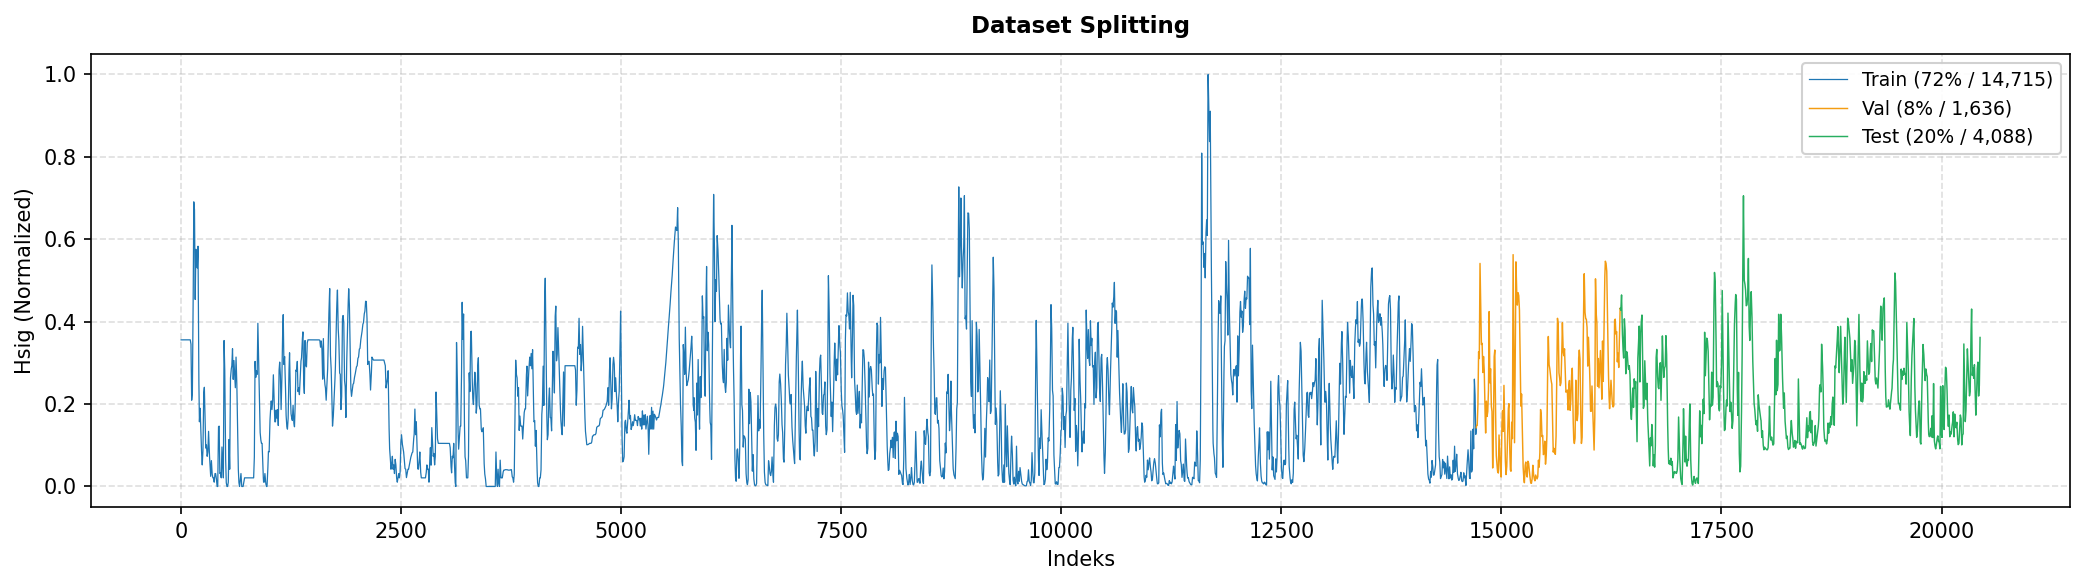

In [ ]:
# ==============================================================================
# TAHAP 5: PARTISI DATASET SECARA KRONOLOGIS
# ==============================================================================
print("=== RENTANG NILAI FITUR ===")
print(f"X_train : Min = {X_train.min():.4f}, Max = {X_train.max():.4f}")
print(f"X_test  : Min = {X_test.min():.4f}, Max = {X_test.max():.4f}")

# Hitung jumlah sampel tiap partisi
n_train = len(y_train)
n_val = len(y_val)
n_test = len(y_test)

# Indeks urutan waktu
idx_tr = np.arange(0, n_train)
idx_va = np.arange(n_train, n_train + n_val)
idx_te = np.arange(n_train + n_val, n_train + n_val + n_test)

plt.figure(figsize=(14, 4), dpi=150)
plt.plot(idx_tr, y_train[:, 1], color='#1f77b4', lw=0.6, label=f'Train (72% / {n_train:,})')
plt.plot(idx_va, y_val[:, 1], color='#f39c12', lw=0.7, label=f'Val (8% / {n_val:,})')
plt.plot(idx_te, y_test[:, 1], color='#27ae60', lw=0.7, label=f'Test (20% / {n_test:,})')

plt.title('Dataset Splitting', fontsize=11, fontweight='bold', pad=10)
plt.xlabel('Indeks', fontsize=10)
plt.ylabel('Hsig (Normalized)', fontsize=10)
plt.grid(True, linestyle='--', alpha=0.4)
plt.legend(loc='upper right', framealpha=0.9, fontsize=9)
plt.tight_layout()
plt.show()

In [ ]:
# Cek nilai maksimum tiap fitur khusus pada data uji
df_test_check = pd.DataFrame(X_test.reshape(-1, len(feature_cols)), columns=feature_cols)
print("=== FITUR YANG MELEBIHI 1.0 PADA DATA UJI ===")
print(df_test_check.max()[df_test_check.max() > 1.0])

=== FITUR YANG MELEBIHI 1.0 PADA DATA UJI ===
WindSeaDir(deg)_cos    1.001601
dtype: float64


# TRAINING EP GRU

In [ ]:
# ==============================================================================
# 1. TRAINING MODEL EP-GRU (17 FITUR INPUT, 2 TARGET OUTPUT)
# ==============================================================================
import copy
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

In [ ]:

# Inisialisasi model membaca len(feature_cols) yang bernilai 17
model = EPGRUModel(
    input_dim=len(feature_cols),      # 17 fitur
    hidden_dim1=64,                   # Layer 1: 64 unit
    hidden_dim2=32,                   # Layer 2: 32 unit
    output_dim=len(target_cols)       # 2 target: WindSpeed & Hsig
).to(device)

criterion = nn.MSELoss()
LEARNING_RATE = 0.001                # Nilai learning rate paling stabil
EPOCHS = 50
PATIENCE = 5                         # Batas toleransi early stopping

optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
best_val_loss = float('inf')
patience_counter = 0
best_model_weights = copy.deepcopy(model.state_dict())

train_loss_history = []
val_loss_history = []

print(f"Memulai Pelatihan EP-GRU, (LR: {LEARNING_RATE}, Patience: {PATIENCE})...\n")

for epoch in range(EPOCHS):
    # --- Fase Training ---
    model.train()
    total_train_loss = 0.0
    for batch_x, batch_y in train_loader:
        batch_x, batch_y = batch_x.to(device), batch_y.to(device)
        optimizer.zero_grad()
        preds = model(batch_x)
        loss = criterion(preds, batch_y)
        loss.backward()
        optimizer.step()
        total_train_loss += loss.item() * batch_x.size(0)

    epoch_train_loss = total_train_loss / len(train_loader.dataset)
    train_loss_history.append(epoch_train_loss)

    # --- Fase Validasi ---
    model.eval()
    total_val_loss = 0.0
    with torch.no_grad():
        for batch_x, batch_y in val_loader:
            batch_x, batch_y = batch_x.to(device), batch_y.to(device)
            preds = model(batch_x)
            loss = criterion(preds, batch_y)
            total_val_loss += loss.item() * batch_x.size(0)

    epoch_val_loss = total_val_loss / len(val_loader.dataset)
    val_loss_history.append(epoch_val_loss)

    print(f"Epoch [{epoch+1:02d}/{EPOCHS}] - Train MSE: {epoch_train_loss:.6f}  |  Val MSE: {epoch_val_loss:.6f}")

    # Checkpoint bobot terbaik
    if epoch_val_loss < best_val_loss:
        best_val_loss = epoch_val_loss
        best_model_weights = copy.deepcopy(model.state_dict())
        torch.save(best_model_weights, 'best_epgru_17fitur.pth')
        patience_counter = 0
    else:
        patience_counter += 1
        if patience_counter >= PATIENCE:
            print(f"\n[Early Stopping] Pelatihan berhenti pada Epoch {epoch+1}. Bobot terbaik dimuat (Val MSE: {best_val_loss:.6f}).")
            break

# Muat bobot model terbaik
model.load_state_dict(best_model_weights)
print("✓ Pelatihan selesai dan bobot terbaik berhasil dimuat!")

Memulai Pelatihan EP-GRU, (LR: 0.001, Patience: 5)...

Epoch [01/50] - Train MSE: 0.001986  |  Val MSE: 0.000640
Epoch [02/50] - Train MSE: 0.000421  |  Val MSE: 0.000412
Epoch [03/50] - Train MSE: 0.000319  |  Val MSE: 0.000462
Epoch [04/50] - Train MSE: 0.000272  |  Val MSE: 0.000264
Epoch [05/50] - Train MSE: 0.000264  |  Val MSE: 0.000278
Epoch [06/50] - Train MSE: 0.000275  |  Val MSE: 0.000280
Epoch [07/50] - Train MSE: 0.000247  |  Val MSE: 0.000338
Epoch [08/50] - Train MSE: 0.000240  |  Val MSE: 0.000236
Epoch [09/50] - Train MSE: 0.000233  |  Val MSE: 0.000237
Epoch [10/50] - Train MSE: 0.000232  |  Val MSE: 0.000221
Epoch [11/50] - Train MSE: 0.000216  |  Val MSE: 0.000240
Epoch [12/50] - Train MSE: 0.000214  |  Val MSE: 0.000249
Epoch [13/50] - Train MSE: 0.000214  |  Val MSE: 0.000249
Epoch [14/50] - Train MSE: 0.000218  |  Val MSE: 0.000237
Epoch [15/50] - Train MSE: 0.000199  |  Val MSE: 0.000262

[Early Stopping] Pelatihan berhenti pada Epoch 15. Bobot terbaik dimuat (V

In [ ]:
# ==============================================================================
# INFERENSI DETERMINISTIK (POINT FORECAST) & INVERSE SCALING
# ==============================================================================
X_test_tensor = torch.FloatTensor(X_test).to(device)

model.eval()
with torch.no_grad():
    test_preds = model(X_test_tensor)

# Kembalikan ke skala asli (knots & meter)
pred_inv = scaler_y.inverse_transform(test_preds.cpu().numpy())
y_test_inv = scaler_y.inverse_transform(y_test)

print("✓ Inferensi Deterministik & Inverse Scaling Selesai!")
print(f"Bentuk output prediksi: {pred_inv.shape}")

✓ Inferensi Deterministik & Inverse Scaling Selesai!
Bentuk output prediksi: (4088, 2)


# Visualisasi

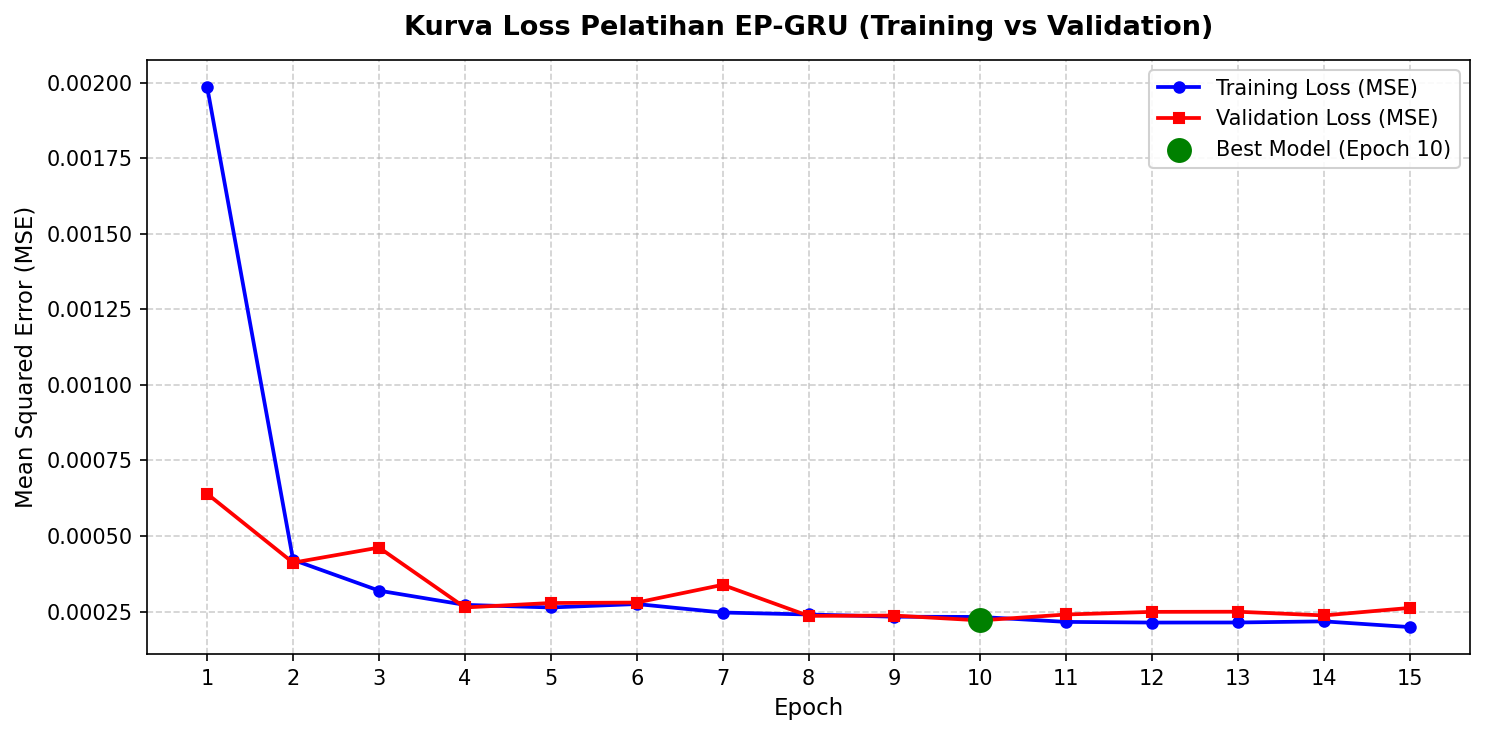

In [ ]:
# ==============================================================================
# 1. VISUALISASI KURVA LOSS (TRAINING VS VALIDATION)
# ==============================================================================
plt.figure(figsize=(10, 5), dpi=150)
epochs_range = range(1, len(train_loss_history) + 1)
best_epoch = int(np.argmin(val_loss_history) + 1)
best_val = min(val_loss_history)

plt.plot(epochs_range, train_loss_history, 'b-o', label='Training Loss (MSE)', linewidth=1.8, markersize=5)
plt.plot(epochs_range, val_loss_history, 'r-s', label='Validation Loss (MSE)', linewidth=1.8, markersize=5)
plt.scatter(best_epoch, best_val, color='green', s=120, zorder=5, label=f'Best Model (Epoch {best_epoch})')

plt.title('Kurva Loss Pelatihan EP-GRU (Training vs Validation)', fontsize=13, fontweight='bold', pad=12)
plt.xlabel('Epoch', fontsize=11)
plt.ylabel('Mean Squared Error (MSE)', fontsize=11)
plt.xticks(epochs_range)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(frameon=True, facecolor='white', framealpha=0.9, fontsize=10)
plt.tight_layout()
plt.show()

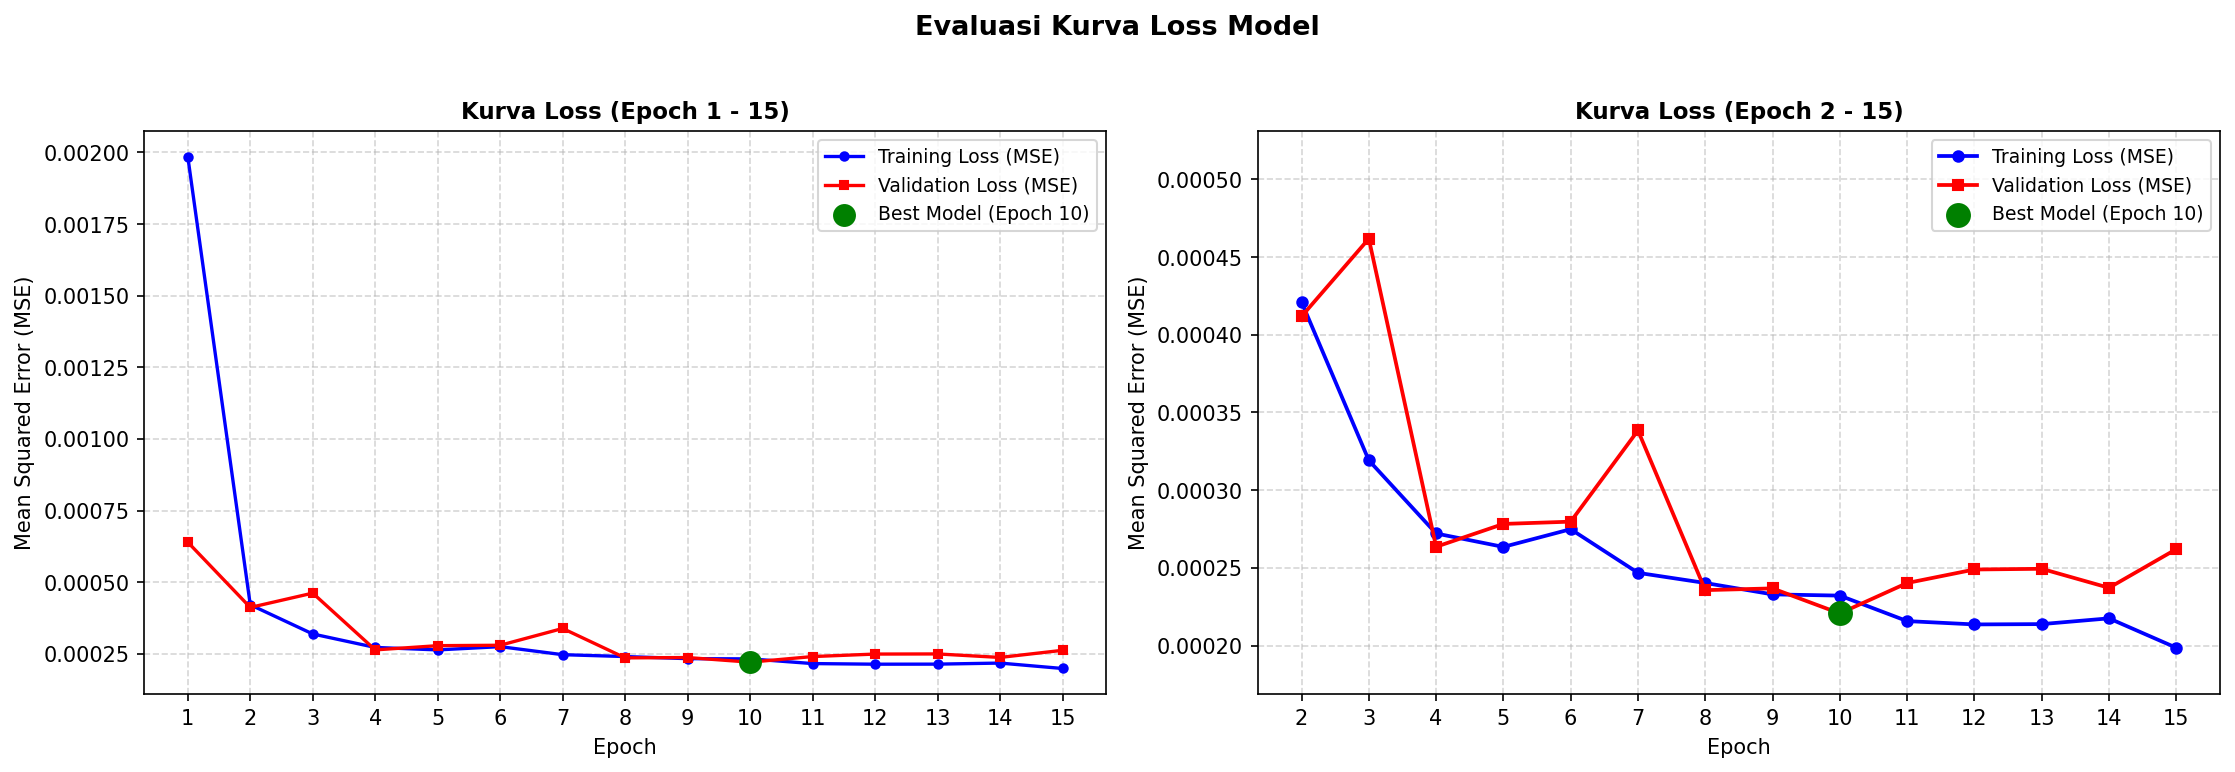

In [ ]:
# ==============================================================================
# VISUALISASI KURVA LOSS DENGAN ZOOM-IN (EPOCH 2 KE ATAS)
# ==============================================================================
fig, axes = plt.subplots(1, 2, figsize=(15, 5), dpi=150)

epochs_range = range(1, len(train_loss_history) + 1)
best_epoch = int(np.argmin(val_loss_history) + 1)
best_val = min(val_loss_history)

# --- Subplot 1: Tampilan Penuh (Epoch 1 s/d Akhir) ---
axes[0].plot(epochs_range, train_loss_history, 'b-o', label='Training Loss (MSE)', linewidth=1.6, markersize=4)
axes[0].plot(epochs_range, val_loss_history, 'r-s', label='Validation Loss (MSE)', linewidth=1.6, markersize=4)
axes[0].scatter(best_epoch, best_val, color='green', s=100, zorder=5, label=f'Best Model (Epoch {best_epoch})')
axes[0].set_title('Kurva Loss (Epoch 1 - 15)', fontsize=11, fontweight='bold')
axes[0].set_xlabel('Epoch', fontsize=10)
axes[0].set_ylabel('Mean Squared Error (MSE)', fontsize=10)
axes[0].set_xticks(epochs_range)
axes[0].grid(True, linestyle='--', alpha=0.5)
axes[0].legend(frameon=True, fontsize=9)

# --- Subplot 2: Perbesaran Dinamika (Mulai dari Epoch 2) ---
start_ep = 2  # Mulai visualisasi dari epoch 2
epochs_zoomed = range(start_ep, len(train_loss_history) + 1)
train_zoomed = train_loss_history[start_ep - 1:]
val_zoomed = val_loss_history[start_ep - 1:]

axes[1].plot(epochs_zoomed, train_zoomed, 'b-o', label='Training Loss (MSE)', linewidth=1.8, markersize=5)
axes[1].plot(epochs_zoomed, val_zoomed, 'r-s', label='Validation Loss (MSE)', linewidth=1.8, markersize=5)
axes[1].scatter(best_epoch, best_val, color='green', s=120, zorder=5, label=f'Best Model (Epoch {best_epoch})')

# Menyesuaikan batas sumbu Y agar riak fluktuasi terlihat proporsional
y_min = min(min(train_zoomed), min(val_zoomed)) * 0.85
y_max = max(max(train_zoomed), max(val_zoomed)) * 1.15
axes[1].set_ylim(y_min, y_max)

axes[1].set_title('Kurva Loss (Epoch 2 - 15)', fontsize=11, fontweight='bold')
axes[1].set_xlabel('Epoch', fontsize=10)
axes[1].set_ylabel('Mean Squared Error (MSE)', fontsize=10)
axes[1].set_xticks(epochs_zoomed)
axes[1].grid(True, linestyle='--', alpha=0.5)
axes[1].legend(frameon=True, fontsize=9)

plt.suptitle('Evaluasi Kurva Loss Model', fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

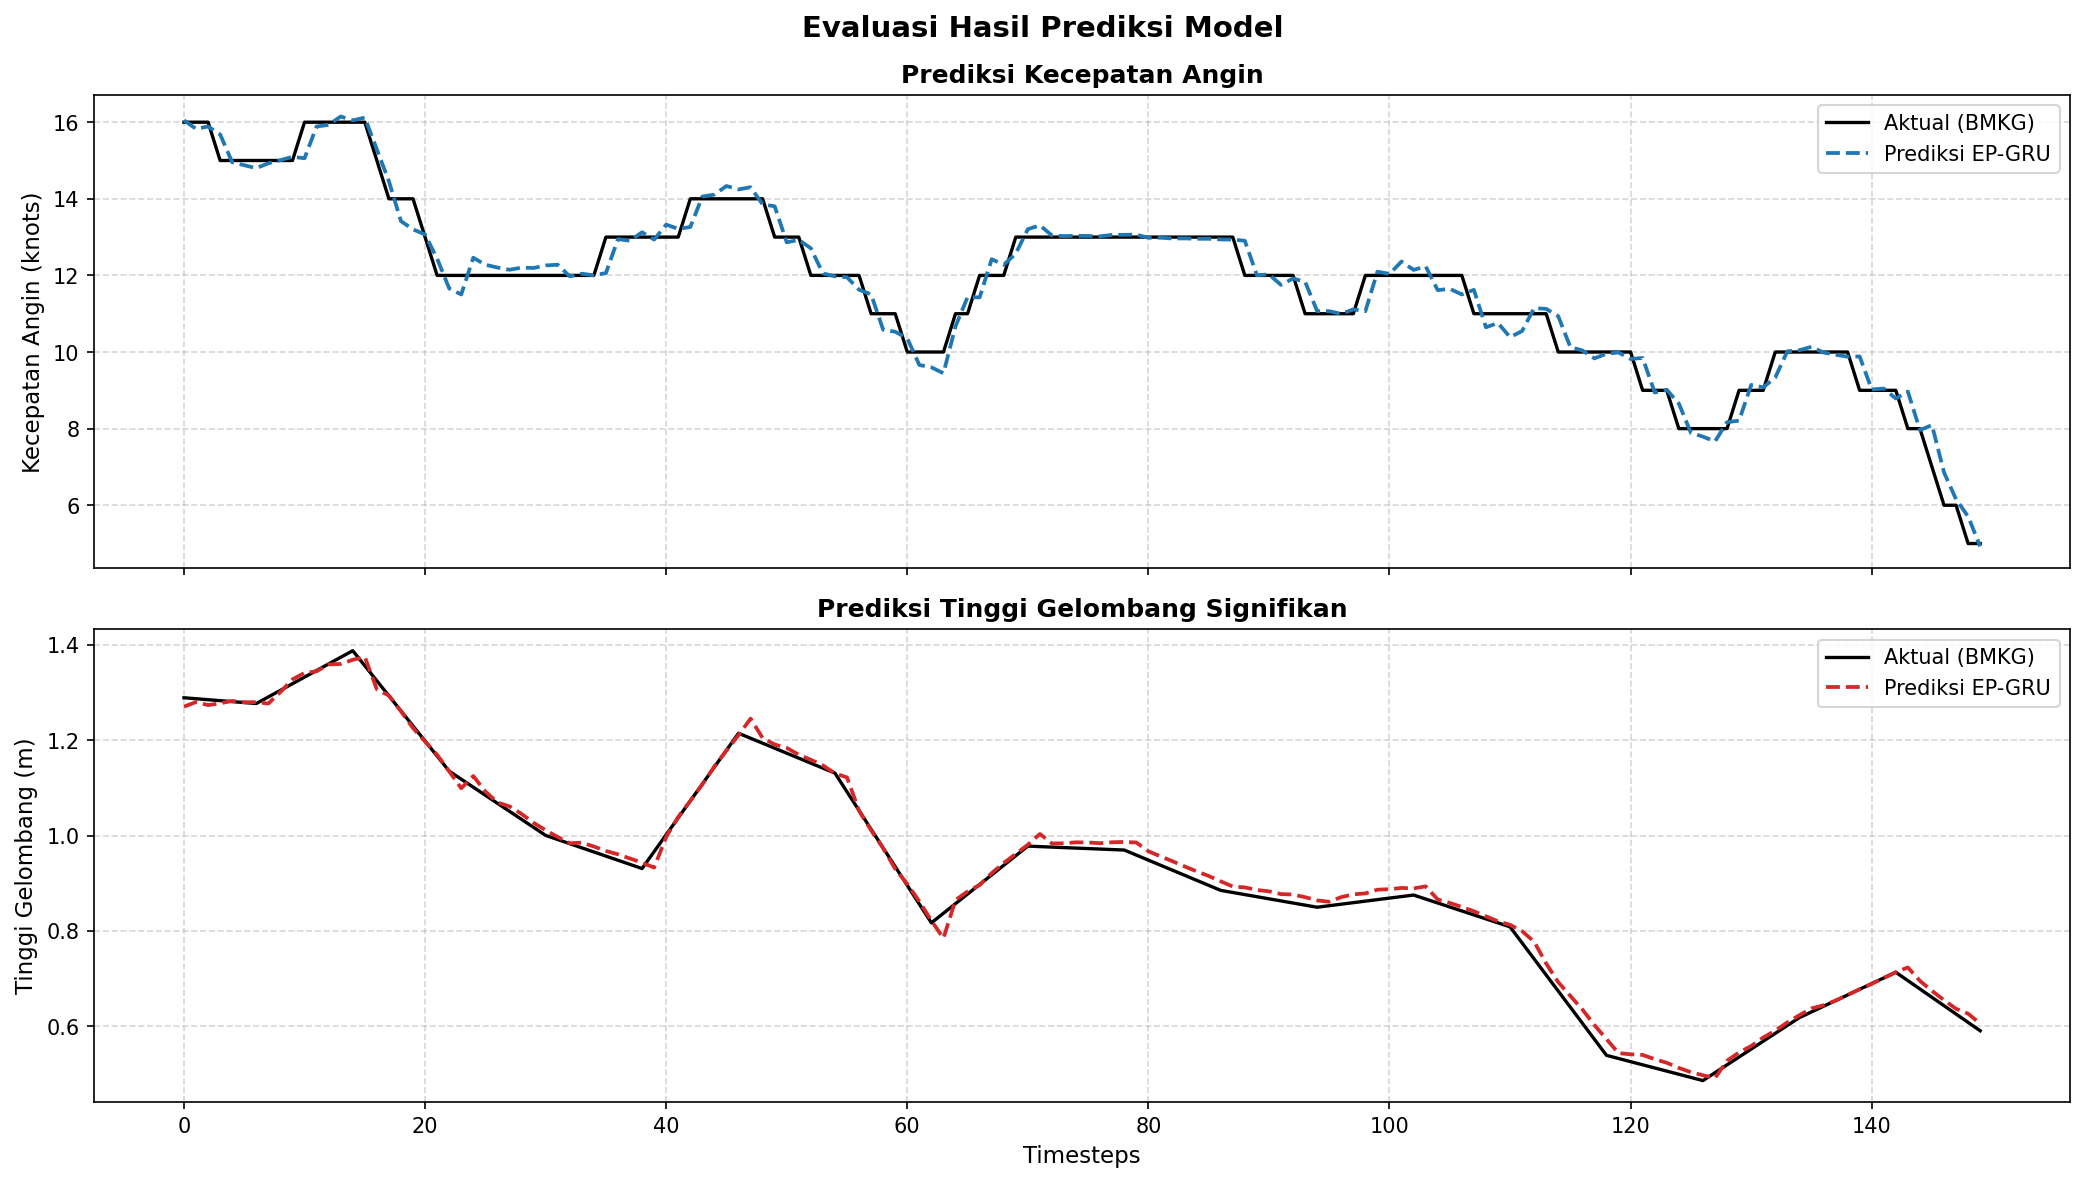

In [ ]:
# ==============================================================================
# 2. VISUALISASI PREDIKSI DETERMINISTIK (AKTUAL VS PREDIKSI EP-GRU)
# ==============================================================================
N_SAMPLES = 150
time_steps = range(N_SAMPLES)

fig, axes = plt.subplots(2, 1, figsize=(14, 8), dpi=150, sharex=True)

# --- Subplot 1: Kecepatan Angin (WindSpeed) ---
axes[0].plot(time_steps, y_test_inv[:N_SAMPLES, 0], color='black', linewidth=1.6, label='Aktual (BMKG)')
axes[0].plot(time_steps, pred_inv[:N_SAMPLES, 0], color='#1f77b4', linestyle='--', linewidth=1.8, label='Prediksi EP-GRU')
axes[0].set_title('Prediksi Kecepatan Angin', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Kecepatan Angin (knots)', fontsize=11)
axes[0].grid(True, linestyle='--', alpha=0.5)
axes[0].legend(loc='upper right', frameon=True)

# --- Subplot 2: Tinggi Gelombang Signifikan (Hsig) ---
axes[1].plot(time_steps, y_test_inv[:N_SAMPLES, 1], color='black', linewidth=1.6, label='Aktual (BMKG)')
axes[1].plot(time_steps, pred_inv[:N_SAMPLES, 1], color='#d62728', linestyle='--', linewidth=1.8, label='Prediksi EP-GRU')
axes[1].set_title('Prediksi Tinggi Gelombang Signifikan', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Timesteps', fontsize=11)
axes[1].set_ylabel('Tinggi Gelombang (m)', fontsize=11)
axes[1].grid(True, linestyle='--', alpha=0.5)
axes[1].legend(loc='upper right', frameon=True)

plt.suptitle('Evaluasi Hasil Prediksi Model', fontsize=14, fontweight='bold', y=0.98)
plt.tight_layout()
plt.show()

# Evaluasi Model

In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

def calculate_mape_filtered(y_true, y_pred, threshold=0.1):
    mask = np.abs(y_true) > threshold
    return np.mean(np.abs((y_true[mask] - y_pred[mask]) / y_true[mask])) * 100.0

eval_summary = []
target_names = ['WindSpeed (knots)', 'Hsig (m)']

for i, col in enumerate(target_names):
    yt = y_test_inv[:, i]
    yp = pred_inv[:, i]

    mae  = mean_absolute_error(yt, yp)
    rmse = np.sqrt(mean_squared_error(yt, yp))
    mape = calculate_mape_filtered(yt, yp)
    r2   = r2_score(yt, yp)

    eval_summary.append({
        'Fitur Target': col,
        'MAE': f"{mae:.4f}",
        'RMSE': f"{rmse:.4f}",
        'MAPE (%)': f"{mape:.2f}%",
        'R2 Score': f"{r2:.4f}"
    })

df_eval = pd.DataFrame(eval_summary)
print("=== TABEL EVALUASI PERFORMA MODEL EP-GRU (DETERMINISTIK) ===")
display(df_eval)

=== TABEL EVALUASI PERFORMA MODEL EP-GRU (DETERMINISTIK) ===


,Fitur Target,MAE,RMSE,MAPE (%),R2 Score
0,WindSpeed (knots),0.3949,0.5062,6.63%,0.9858
1,Hsig (m),0.0186,0.0238,4.15%,0.9951


# Integrated Gradient

In [ ]:
# ==============================================================================
# INTEGRATED GRADIENTS (EXPLAINABLE AI) UNTUK EP-GRU
# Menghitung atribusi/kontribusi tiap fitur input terhadap output bivariat
# ==============================================================================
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

model.eval()
dev = next(model.parameters()).device

def compute_integrated_gradients(model, input_seq, baseline_seq=None, target_idx=0, steps=40):
    """
    Menghitung Integrated Gradients untuk 1 sampel deret waktu berdimensi (24, 18).
    target_idx: 0 -> WindSpeed(knots), 1 -> Hsig(m)
    """
    if baseline_seq is None:
        # Baseline nol (dalam MinMax scaler merepresentasikan nilai minimum fitur)
        baseline_seq = torch.zeros_like(input_seq)

    # Interpolasi garis linier alpha dari baseline (0.0) ke input aktual (1.0)
    alphas = torch.linspace(0.0, 1.0, steps + 1, device=dev)

    # Shape: (steps + 1, seq_len, num_features)
    interpolated = baseline_seq.unsqueeze(0) + alphas[:, None, None] * (input_seq - baseline_seq).unsqueeze(0)
    interpolated = interpolated.clone().detach().requires_grad_(True)

    # Forward pass untuk seluruh batch interpolasi
    preds = model(interpolated)
    target_preds = preds[:, target_idx]

    # Hitung gradien output target terhadap masukan interpolasi
    grads = torch.autograd.grad(
        outputs=target_preds.sum(),
        inputs=interpolated,
        retain_graph=False,
        create_graph=False
    )[0]

    # Integrasi pendekatan aturan trapesium (Riemann sum)
    avg_grads = (grads[:-1] + grads[1:]) / 2.0
    ig = (input_seq - baseline_seq) * avg_grads.mean(dim=0)

    # Agregasi nilai absolut atribusi sepanjang 24 timesteps -> (num_features,)
    return ig.abs().mean(dim=0).detach().cpu().numpy()

# Evaluasi pada 100 sampel acak dari data uji
np.random.seed(42)
sample_indices = np.random.choice(len(X_test), size=min(100, len(X_test)), replace=False)

ig_wind_list = []
ig_hsig_list = []

print(f"Menghitung Integrated Gradients pada {len(sample_indices)} sampel data uji...")
with torch.set_grad_enabled(True):
    for idx in sample_indices:
        x_sample = torch.tensor(X_test[idx], dtype=torch.float32, device=dev)
        ig_wind_list.append(compute_integrated_gradients(model, x_sample, target_idx=0, steps=30))
        ig_hsig_list.append(compute_integrated_gradients(model, x_sample, target_idx=1, steps=30))

mean_ig_wind = np.mean(ig_wind_list, axis=0)
mean_ig_hsig = np.mean(ig_hsig_list, axis=0)

df_ig = pd.DataFrame({
    'Feature': feature_cols,
    'Importance_WindSpeed': mean_ig_wind,
    'Importance_Hsig': mean_ig_hsig
})


Menghitung Integrated Gradients pada 100 sampel data uji...


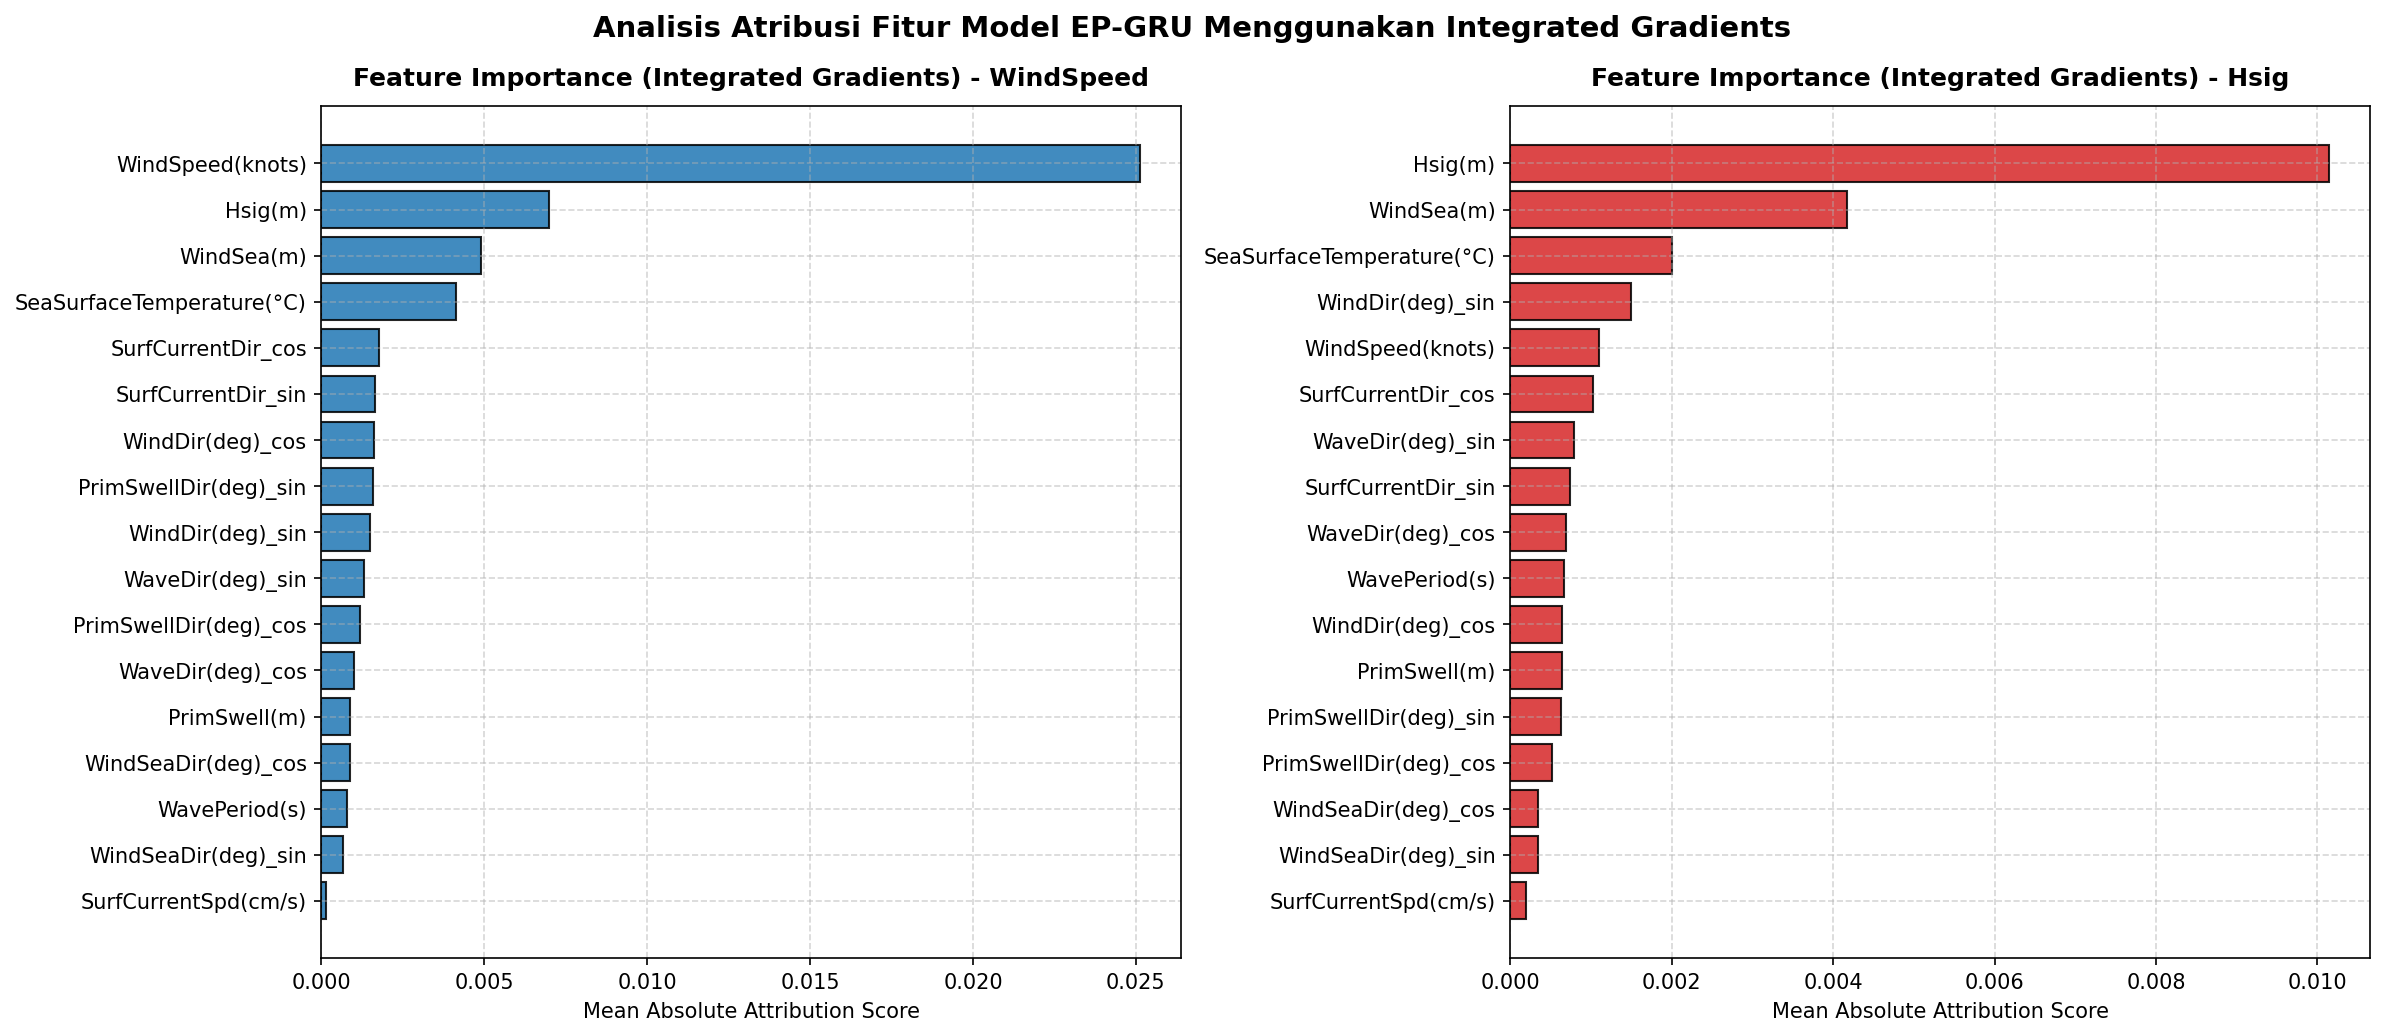


=== RANKING ATRIBUSI FITUR TERHADAP TARGET BIVARIAT ===


,Feature,Importance_WindSpeed,Importance_Hsig
0,Hsig(m),0.006983,0.010144
1,WindSea(m),0.004890,0.004170
2,SeaSurfaceTemperature(°C),0.004131,0.002007
3,WindDir(deg)_sin,0.001503,0.001498
4,WindSpeed(knots),0.025138,0.001102
5,SurfCurrentDir_cos,0.001760,0.001030
6,WaveDir(deg)_sin,0.001293,0.000795
7,SurfCurrentDir_sin,0.001630,0.000738
8,WaveDir(deg)_cos,0.000999,0.000689
9,WavePeriod(s),0.000780,0.000668


In [ ]:

# ==============================================================================
# VISUALISASI PERINGKAT KONTRIBUSI FITUR (FEATURE IMPORTANCE)
# ==============================================================================
fig, axes = plt.subplots(1, 2, figsize=(16, 7), dpi=150)

# 1. Plot untuk WindSpeed
df_wind_sorted = df_ig.sort_values(by='Importance_WindSpeed', ascending=True)
axes[0].barh(df_wind_sorted['Feature'], df_wind_sorted['Importance_WindSpeed'], color='#1f77b4', edgecolor='black', alpha=0.85)
axes[0].set_title('Feature Importance (Integrated Gradients) - WindSpeed', fontsize=12, fontweight='bold', pad=10)
axes[0].set_xlabel('Mean Absolute Attribution Score', fontsize=10)
axes[0].grid(True, linestyle='--', alpha=0.5)

# 2. Plot untuk Hsig
df_hsig_sorted = df_ig.sort_values(by='Importance_Hsig', ascending=True)
axes[1].barh(df_hsig_sorted['Feature'], df_hsig_sorted['Importance_Hsig'], color='#d62728', edgecolor='black', alpha=0.85)
axes[1].set_title('Feature Importance (Integrated Gradients) - Hsig', fontsize=12, fontweight='bold', pad=10)
axes[1].set_xlabel('Mean Absolute Attribution Score', fontsize=10)
axes[1].grid(True, linestyle='--', alpha=0.5)

plt.suptitle('Analisis Atribusi Fitur Model EP-GRU Menggunakan Integrated Gradients', fontsize=14, fontweight='bold', y=0.98)
plt.tight_layout()
plt.show()

# Menampilkan tabel ranking fitur
print("\n=== RANKING ATRIBUSI FITUR TERHADAP TARGET BIVARIAT ===")
display(df_ig.sort_values(by='Importance_Hsig', ascending=False).reset_index(drop=True))